# Which NAD83 realization are the checkpoint source coordinates in? (exploratory)

29,591 checkpoints have source coordinates recorded in a datum other than NAD83(2011) (`qc_horizontal_flag = source_datum_not_nad83_2011`). Their published lon,lat positions are mostly the source coordinates **re-labelled** NAD83(2011), not transformed ([quality assessment](checkpoints_quality_assessment.ipynb), Part 4). That is right if the recorded label is a generic "NAD83" for data actually in NAD83(2011), and 0.2–1 m wrong if the label is true. This notebook asks whether each checkpoint's own OPR DEM can tell which.

**The test.** Where a checkpoint's recorded realization differs from its OPR DEM's, the two labels predict different positions on the DEM grid:

- **same frame**: the labels are two names for one frame; the source easting/northing go onto the DEM grid by a projection change alone;
- **labels true**: PROJ's realization transformation applies (NADCON5 etc.).

On sloping ground the right position gives tighter DEM − checkpoint residuals. `scripts/position_test_checkpoints_3dep.py` samples a DEM patch around each checkpoint (bilinear, in the DEM's own grid, after the approach in stac-3dep-1m's `source_dem_check.py`), pools a project's work units, and compares the NMAD of DEM − checkpoint (each work unit's median removed) on points with slope ≥ 5° at both positions. A paired bootstrap gives a 95% interval for NMAD(labels true) − NMAD(same frame); a verdict needs the interval to exclude 0. Source coordinates come from `source_horizontal_crs_qc` / `source_axes_swapped_qc` (the repaired source coordinate system).

This notebook reads the script's saved results (`data/checkpoints_3dep_position_test*.csv`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

res = pd.read_csv("../data/checkpoints_3dep_position_test.csv")
wu = pd.read_csv("../data/checkpoints_3dep_position_test_workunits.csv")
print(f"{len(wu)} work units with checkpoint/DEM labels that may differ")
wu.status.value_counts()

391 work units with checkpoint/DEM labels that may differ


status
labels agree (not testable)    162
sampled                        150
no transformation               79
Name: count, dtype: int64

## 1. Most checkpoints cannot be tested this way

Most flagged checkpoints carry the **same** realization label as their own OPR DEM (both labels come from the same project), and then the two positions coincide: checkpoint and DEM agree whatever the true realization is. Those are not in the table above at all. Of the work units whose labels may differ, many still turn out to name one frame ("labels agree"), and many DEMs name no realization at all ("no transformation": their CRS says *Unknown datum based upon the GRS 1980 ellipsoid*).

In [2]:
wu[wu.status != "sampled"].groupby(["status", "src_datum", "dem_datum"]).size().rename("work units").to_frame()

work units
status                      src_datum     dem_datum                                                  
labels agree (not testable) NAD83         NAD83                                                   106
                            NAD83(2011)   GCS_NAD83_2011                                            1
                                          NAD83                                                     1
                                          NAD83(2011)                                              33
                            NAD83(CORS96) NAD83(CORS96)                                            12
                            NAD83(HARN)   GCS_NAD83_ILLINOIS_HPGN                                   2
                                          NAD83(HARN)                                               7
no transformation           NAD83         Unknown datum based upon the GRS 1980 ellipsoid           9
                            NAD83(2011)   GCS_North_American_1983_2011                              1
                                          Unknown datum based upon the GRS 1980 ellipsoid          36
                            NAD83(CORS96) Unknown datum based upon the GRS 1980 ellipsoid          12
                            NAD83(HARN)   Unknown datum based upon the GRS 1980 ellipsoid          21

## 2. Results for the testable projects

verdict
undecided (too few sloped points)    50
undecided                            30
same frame                            2


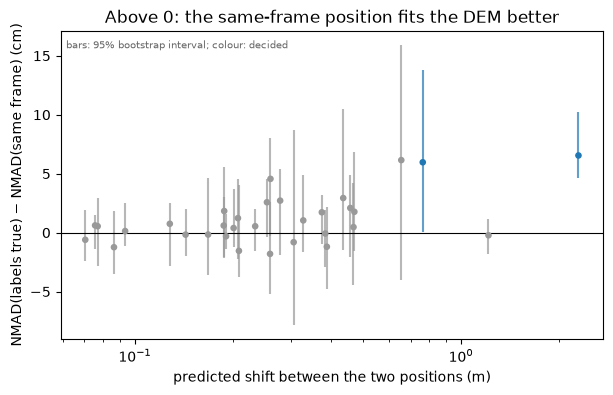

21 of 32 groups lean 'same frame' (sign test p = 0.11); with a predicted shift >= 0.4 m: 7 of 8


In [3]:
t = res[np.isfinite(res.diff_lo)].copy()
print(res.verdict.value_counts().to_string())
fig, ax = plt.subplots(figsize=(7, 4))
mid = (t.diff_lo + t.diff_hi) / 2
colors = t.verdict.map({"same frame": "tab:blue", "labels true": "tab:orange"}).fillna("0.6")
ax.errorbar(t.shift_m, mid * 100, yerr=[(mid - t.diff_lo) * 100, (t.diff_hi - mid) * 100],
            fmt="none", ecolor=colors, alpha=0.7)
ax.scatter(t.shift_m, (t.nmad_shift - t.nmad_same) * 100, c=colors, s=14, zorder=3)
ax.axhline(0, color="k", lw=0.8)
ax.set_xscale("log")
ax.set(xlabel="predicted shift between the two positions (m)",
       ylabel="NMAD(labels true) − NMAD(same frame) (cm)",
       title="Above 0: the same-frame position fits the DEM better")
ax.text(0.01, 0.97, "bars: 95% bootstrap interval; colour: decided", transform=ax.transAxes,
        fontsize=7, color="0.4", va="top")
plt.show()
fav = (t.nmad_same < t.nmad_shift)
print(f"{fav.sum()} of {len(t)} groups lean 'same frame' (sign test p = {binomtest(int(fav.sum()), len(t)).pvalue:.2f}); "
      f"with a predicted shift >= 0.4 m: {fav[t.shift_m >= 0.4].sum()} of {(t.shift_m >= 0.4).sum()}")

In [4]:
cols = ["project_id", "src_crs", "dem_crs", "n", "n_sloped", "shift_m", "nmad_same", "nmad_shift",
        "diff_lo", "diff_hi", "verdict"]
t.sort_values("shift_m", ascending=False)[cols].round(3).head(15)

,project_id,src_crs,dem_crs,n,n_sloped,shift_m,nmad_same,nmad_shift,diff_lo,diff_hi,verdict
0,12384,NAD83 / UTM zone 10N,NAD_1983_StatePlane_California_II_FIPS_0402_Fe...,327,173,2.290,0.059,0.124,0.046,0.102,same frame
7,26345,NAD83(HARN) / Illinois East (ftUS),NAD83_HARN_Illinois_East_ftUS,1270,235,1.213,0.107,0.104,-0.018,0.012,undecided
1,53868,NAD83(2011) / UTM zone 10N,NAD83 / UTM zone 10N,139,24,0.763,0.090,0.150,0.000,0.138,same frame
17,50604,NAD83(2011) / UTM zone 11N,NAD83 / UTM zone 11N,91,17,0.656,0.087,0.149,-0.040,0.159,undecided
16,48664,NAD83(2011) / UTM zone 15N,NAD83 / UTM zone 15N,452,38,0.471,0.059,0.077,-0.016,0.069,undecided
23,62435,NAD83(2011) / UTM zone 14N,NAD83 / UTM zone 14N,404,28,0.468,0.051,0.055,-0.045,0.042,undecided
4,20870,NAD83(NSRS2007) / North Dakota North (ft),NAD83 / North Dakota North (ft),241,39,0.457,0.067,0.088,-0.020,0.049,undecided
18,57819,NAD83(HARN) / UTM zone 10N,NAD83 / UTM zone 10N,153,34,0.435,0.100,0.129,-0.015,0.105,undecided
22,60607,NAD83(2011) / UTM zone 12N,NAD83 / UTM zone 12N,328,57,0.388,0.083,0.071,-0.047,0.022,undecided
29,80589,NAD83(2011) / UTM zone 10N,NAD83 / UTM zone 10N,171,98,0.383,0.066,0.065,-0.029,0.020,undecided


## 3. What this shows

- **Decided:** two projects, both *same frame*. The clear one is CA_Sonoma_2013 (project 12384), where the repaired source coordinate system is NAD83 / UTM 10N and the OPR DEM is NAD83(2011) / UTM 10N: transforming between the labels would move points 2.3 m, and the residual spread doubles (5.9 → 12.4 cm) when it is applied. The Sonoma source coordinates are in the DEM's frame, so their "NAD83" label (inherited from the recorded state plane code) is a generic label for NAD83(2011) data, or the DEM's label is.
- **Lean:** across the testable projects most lean *same frame*, more clearly where the predicted shift is large enough for the test to have power (≥ 0.4 m), but individually they are within noise.
- **Why so few decisions:** checkpoints are chosen on flat open ground (NVA by specification), so a 0.1–0.5 m horizontal shift barely changes the DEM height at them. A median slope of ~2° gives ~1 cm of signal per 0.3 m of shift, under the ~6 cm checkpoint-vs-DEM noise.

**Conclusion so far:** checkpoints alone can decide a realization only where the shift is large (≳ 1 m) or the project has many sloped checkpoints. The evidence points the same way as the published lon,lat positions (USGS's re-label), but it is not strong enough to repair positions.

**What would decide it:**
1. **DEM-to-DEM co-registration** of overlapping OPR projects with different realization labels, on all sloped pixels rather than at a few checkpoints (stac-3dep-1m's `source_dem_check.py` co-registration). Much more statistical power; heavier compute (full tiles), a candidate for SkyPilot on Hyak or AWS.
2. **The contractors' survey reports** (linked from the release's `Sources.csv`), which usually state the control and realization.
3. **The same test for the "same label" majority** is impossible in principle: checkpoint and DEM share a frame by construction.